# **NBA Shot Data Analysis & Visualization Report**
> This references the pioneering visualization methodologies of **Bradley Fay (py-Goldsberry)** and **Savvas Tjortjoglou**, with custom geometric micro-adjustments applied to match official NBA court specifications. The data is leveraged to construct both high-resolution scatter plots and multi-dimensional cluster accuracy heatmaps.

---

### Drawing The Court
This court drawing function is based on Bradley Fay and Savvas Tjortjoglou's open-source code with updated exact geometry:
* **Corner Three Lines**: Modified to exactly **`136.977`** units high to form a perfect tangent with the arc.
* **Three-Point Arc Theta**: Calculated precisely from **`22.132°` to `157.868°`** for flawless line intersection.

**References:**
* [Bradley Fay - py-Goldsberry Repository](https://github.com/bradleyfay/py-Goldsberry/blob/main/docs/Visualizing%20NBA%20Shots%20with%20py-Goldsberry.ipynb)
* [Savvas Tjortjoglou - How to Create NBA Shot Charts in Python](http://savvastjortjoglou.com/nba-shot-sharts.html)



In [113]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Arc
import numpy as np

def draw_court(ax=None, color='black', lw=2, outer_lines=False):
    """nba_api coordinates is 10 times of a feet"""
    if ax is None:
        ax = plt.gca()

    # Hoop - Radius 9in (9/12*10=7.5)
    hoop = Circle((0, 0), radius=7.5, linewidth=lw, color=color, fill=False)
    #Backboard - Width 6ft (6*10=60)
    backboard = Rectangle((-30, -7.5), 60, -1, linewidth=lw, color=color)

    # 3-Point Line (Corners) - 22ft from the basket
    left_corner_3 = Rectangle((-220, -47.5), 0, 136.977, linewidth=lw, color=color)
    right_corner_3 = Rectangle((220, -47.5), 0, 136.977, linewidth=lw, color=color)
    # 3-Point Line (Top of Arc) - Radius 23ft 9in
    three_point_arc = Arc((0, 0), 475, 475, theta1=22.132, theta2=157.868, linewidth=lw, color=color)

    # Restricted Area - Radius 4ft
    restricted_area = Arc((0, 0), 80, 80, theta1=0, theta2=180, linewidth=lw, color=color)

    # The Paint/Key - 16ft x 19ft
    paint_box = Rectangle((-80, -47.5), 160, 190, linewidth=lw, color=color, fill=False)
    # Free Throw - 6ft
    free_throw_arc = Arc((0, 142.5), 120, 120, theta1=0, theta2=180, linewidth=lw, color=color)

    
    court_elements = [hoop, backboard, left_corner_3, right_corner_3,
                      three_point_arc, restricted_area, paint_box,
                      free_throw_arc]

    if outer_lines:
        court_outer = patches.Rectangle((-250, -47.5), 500, 470, linewidth=lw, color=color, fill=False)
        court_elements.append(court_outer)

    for element in court_elements:
        ax.add_patch(element)

    ax.set_xlim(-252, 252)
    ax.set_ylim(-49, 423)
    ax.set_aspect('equal')
    ax.axis('off')

    return ax


### Stephen Curry Shot Chart (Scatter Plot)

With the high-fidelity half-court canvas established, we overlay the historical regular-season shot data for **Stephen Curry**. 

Utilizing Pandas boolean indexing, the dataset is isolated by field goal outcome to display attempts simultaneously on the court:
* **Green Circles (Made)**: Highlight precise locations where shots successfully dropped.
* **Red Circles (Missed)**: Illustrate positions resulting in a missed attempt.

This scatter plot provides an instant, granular look at Stephen Curry’s unprecedented volume, his unlimited range way beyond the arc, and how he systematically warps opposing defenses by stretching court boundaries.

In [ ]:
import pandas as pd

data = pd.read_csv('data/shotlog_2014-15_preprocessed.csv')
data_cluster = pd.read_csv('data/shotlog_2014-15_with_clusters.csv')


Saved csv


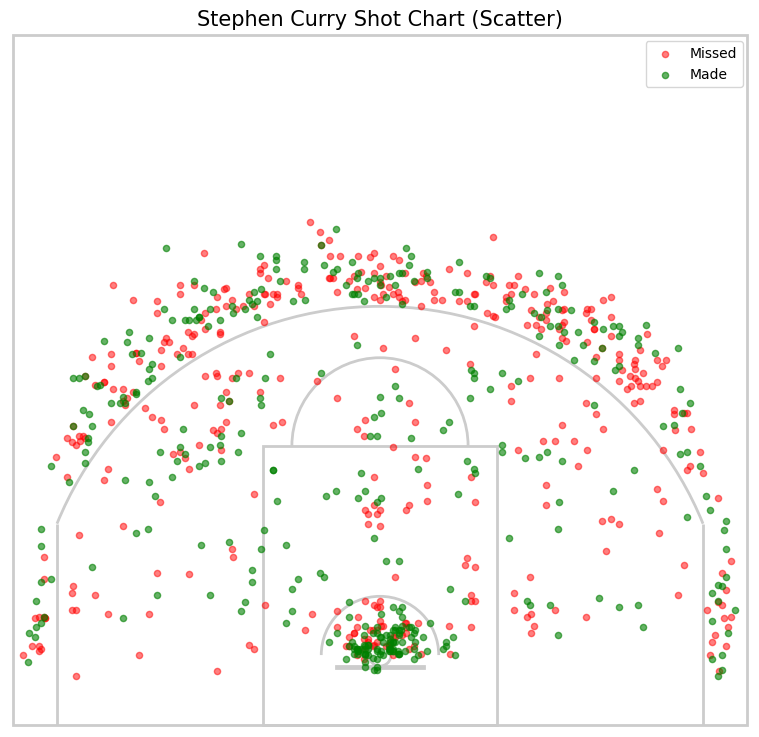

In [110]:
made_shots = data_cluster[(data_cluster['SHOT_MADE_FLAG']==1) & (data_cluster['PLAYER_ID']==201939)] #player_id = 201939 is curry
missed_shots = data_cluster[(data_cluster['SHOT_MADE_FLAG']==0) & (data_cluster['PLAYER_ID']==201939)]

plt.figure(figsize=(10, 9))
ax = plt.gca()
draw_court(ax, color='#cccccc', outer_lines=True)


ax.scatter(missed_shots['LOC_X'], missed_shots['LOC_Y'], c='red', alpha=0.5, s=20, label='Missed')
ax.scatter(made_shots['LOC_X'], made_shots['LOC_Y'], c='green', alpha=0.6, s=20, label='Made')

plt.title("Stephen Curry Shot Chart (Scatter)", fontsize=15)
plt.legend(loc='upper right')
plt.show()


### Shot Zone Accuracy: League Average vs. 6 Archetype Clusters
This chart tracks shot zone efficiency by combining `SHOT_ZONE_BASIC` and `SHOT_ZONE_AREA`. To provide maximum contrast, it uses a unified **5-tier absolute color scale** calibrated directly against league baseline numbers:

* 🟢 **Deep Green (`#006400`) [≥ 56.0%]**: Elite efficiency / rim finishing.
* 🟩 **Vibrant Green (`#28a745`) [44.0% - 55.9%]**: Above-average paint floaters and mid-range.
* 🟨 **Warm Yellow (`#fff3cd`) [36.0% - 43.9%]**: **League Average Zone** (mid-range, paint, and corner 3s).
* 🔴 **Vibrant Red (`#dc3545`) [28.0% - 35.9%]**: Below-average efficiency (average above-the-break 3 range).
* 🔺 **Deep Maroon (`#8b0000`) [< 28.0%]**: Cold shooting / inefficient zones.

The first plot shows the **League Average Benchmark**, followed by a 2x3 grid displaying the **6 Archetype Clusters** generated via machine learning. Each zone prints **"Accuracy% (Made/Attempts)"** over its corresponding efficiency color block to instantly expose the spacing capabilities and tactical footprint of each group.

In [103]:
zone_text_positions = {
    ('Above the Break 3', 'Center(C)'): (0, 260),
    ('Above the Break 3', 'Left Side Center(LC)'): (-160, 230),
    ('Above the Break 3', 'Right Side Center(RC)'): (160, 230),
    ('Left Corner 3', 'Left Side(L)'): (-235, 10),
    ('Right Corner 3', 'Right Side(R)'): (235, 10),
    ('Restricted Area', 'Center(C)'): (0, 15),
    ('In The Paint (Non-RA)', 'Center(C)'): (0, 95),
    ('In The Paint (Non-RA)', 'Left Side(L)'): (-55, 45),
    ('In The Paint (Non-RA)', 'Right Side(R)'): (55, 45),
    ('Mid-Range', 'Center(C)'): (0, 165),
    ('Mid-Range', 'Left Side Center(LC)'): (-110, 150),
    ('Mid-Range', 'Right Side Center(RC)'): (110, 150),
    ('Mid-Range', 'Left Side(L)'): (-165, 45),
    ('Mid-Range', 'Right Side(R)'): (165, 45),
    ('Backcourt', 'Back Court(BC)'): (0, 380),
    ('Above the Break 3', 'Back Court(BC)'): (0, 340)
}

def acc_color(acc):
    if acc >= 0.55:
        return '#006400', 'white'
    elif acc >= 0.45:
        return '#28a745', 'white'
    elif acc >= 0.40:
        return '#90ee90', 'black'
    elif acc >= 0.34:
        return '#fff3cd', 'black'
    elif acc >= 0.28:
        return '#dc3545', 'white'
    else:
        return '#8b0000', 'white'


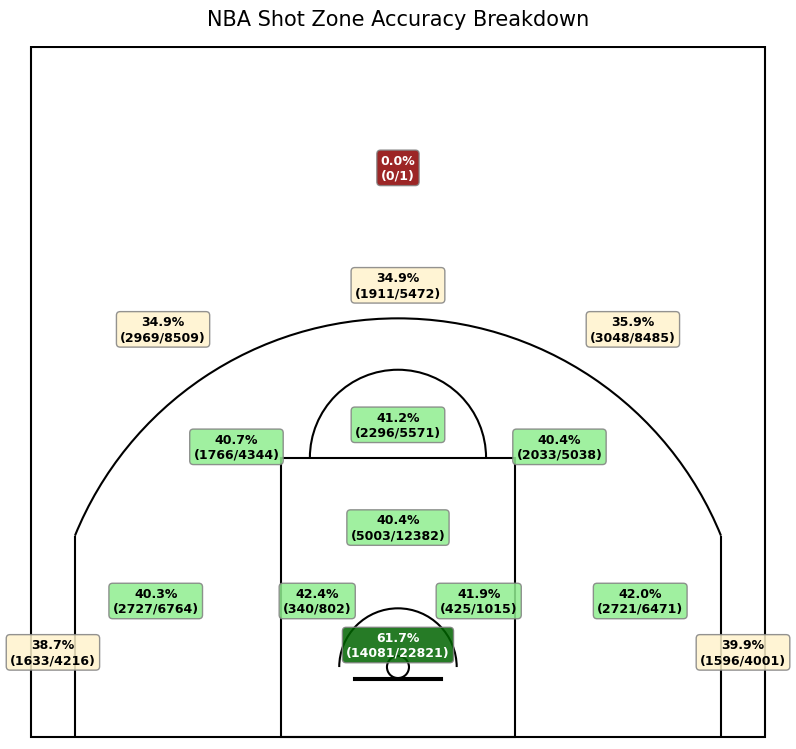

In [112]:
zone_stats = data.groupby(['SHOT_ZONE_BASIC', 'SHOT_ZONE_AREA']).agg(
    total_shots=('SHOT_MADE_FLAG', 'count'),
    made_shots=('SHOT_MADE_FLAG', 'sum')
).reset_index()

zone_stats['accuracy'] = zone_stats['made_shots']/zone_stats['total_shots']


plt.figure(figsize=(10, 9))
ax = plt.gca()
draw_court(ax, color='black', lw=1.5, outer_lines=True)

for _, row in zone_stats.iterrows():
    basic = row['SHOT_ZONE_BASIC']
    area = row['SHOT_ZONE_AREA']
    acc = row['accuracy']
    total = row['total_shots']
    

    pos = zone_text_positions.get((basic, area))
    if pos is None:
        continue
        
    text_label = f"{acc:.1%}\n({int(row['made_shots'])}/{total})"

    bg_color, text_color = acc_color(acc)

    ax.text(pos[0], pos[1], text_label, 
            color=text_color, fontsize=9, weight='bold',
            ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.3', facecolor=bg_color, edgecolor='gray', alpha=0.85))

plt.title("NBA Shot Zone Accuracy Breakdown", fontsize=15, pad=15)
plt.show()


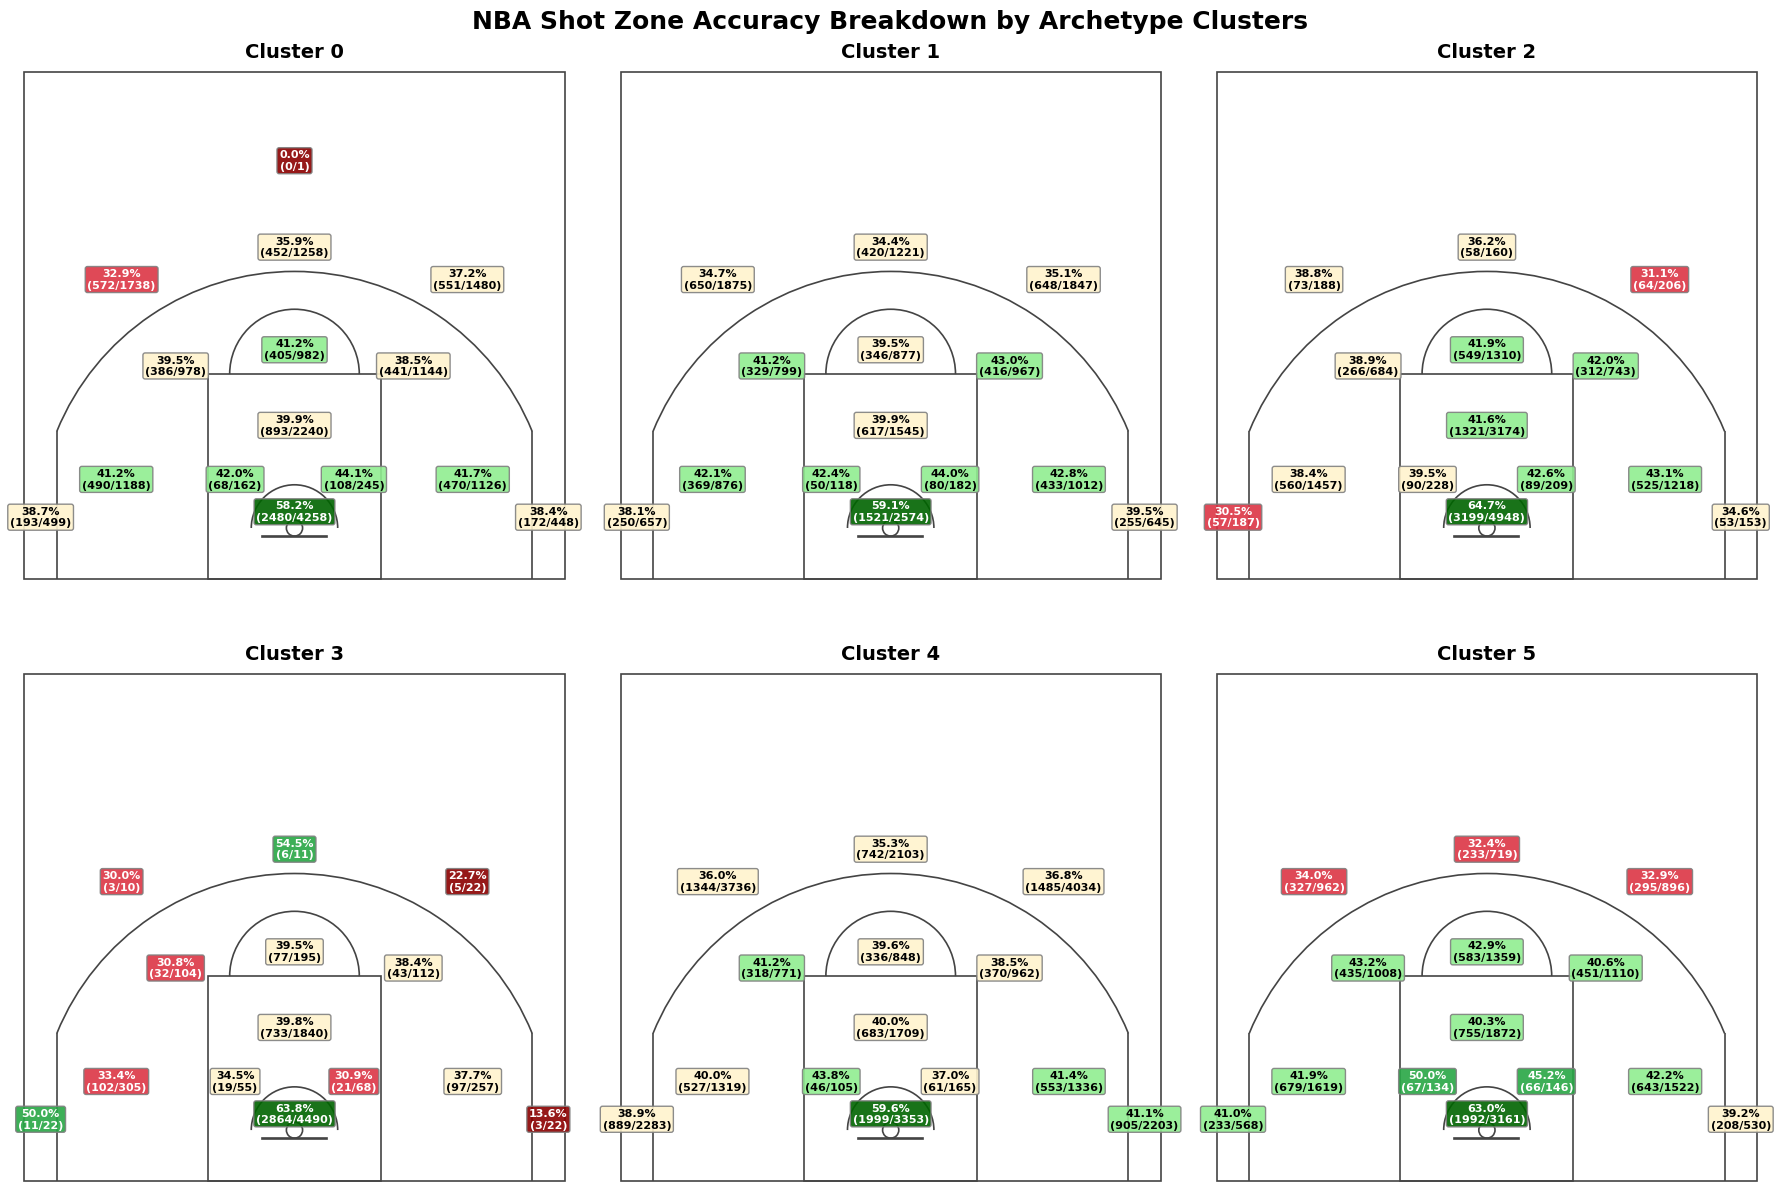

In [ ]:
df_stats = pd.read_csv('data/cluster_zone_stat.csv')

fig, axes = plt.subplots(2, 3, figsize=(18, 13))
axes = axes.flatten()

for cluster_id in range(6):
    ax = axes[cluster_id]

    draw_court(ax, color='#444444', lw=1.2, outer_lines=True)
    
    cluster_data = df_stats[df_stats['ARCHETYPE_CLUSTER']==cluster_id]
    for _, row in cluster_data.iterrows():
        basic = row['SHOT_ZONE_BASIC']
        area = row['SHOT_ZONE_AREA']
        acc = row['ACCURACY']
        total = int(row['count'])
        made = int(row['sum'])
        
        pos = zone_text_positions.get((basic, area))
        if pos is None:
            continue
            
        text_label = f"{acc:.1%}\n({made}/{total})"
        bg_color, text_color = acc_color(acc)
            
        ax.text(pos[0], pos[1], text_label, 
                color=text_color, fontsize=8, weight='bold',
                ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.2', facecolor=bg_color, edgecolor='gray', alpha=0.9))
                
    ax.set_title(f"Cluster {cluster_id}", fontsize=14, weight='bold', pad=10)

plt.suptitle("NBA Shot Zone Accuracy Breakdown by Archetype Clusters", fontsize=18, weight='bold', y=0.96)
plt.tight_layout()
plt.show()